# 第 2 節｜BERT 二元分類微調（高中生練習版）

這次只做**一個二元分類任務**：判斷留言是否表示「已確認參加校園園遊會」。不進行多類別微調。

| `label` | 代表意義 | 留言例子 |
|---|---|---|
| `1` | 已確認會參加 | 我當天會到場幫忙。 |
| `0` | 尚未確認會參加（包含無法參加、尚未決定） | 那天不能到。／我還不確定。 |

500 筆留言為模擬資料。**標籤 0 不等於一定不參加。**

**練習方式：**保留 5 組「Markdown 範例 → 空白 Code Cell」，其餘進階設定直接執行；建議使用 Colab **T4 GPU**。本課將資料分為 Train、Validation、Test，觀察兩條 Loss 曲線。

## 準備環境｜先確認 CSV 在 Colab 伺服器上

**重要：這份 Notebook 的執行環境在 Colab 伺服器，不是你的 Windows／macOS 電腦。** 就算在 VS Code 開啟本機 CSV，Colab 上的 Python 也不一定能讀到。

1. 請先將 **`03_校園園遊會留言_500筆_二元分類.csv`** 上傳到 **Colab 遠端執行環境的 `/content` 資料夾**（不是只有放在 VS Code 本機專案資料夾）。
2. 上傳後，再執行下方「練習 1」。若看到 `FileNotFoundError`，請先確認遠端檔案已上傳、檔名完全相同。
3. 使用 Colab 網頁版時可用左側「檔案 → 上傳」；使用 VS Code 連線時，要確定檔案確實到了**遠端執行環境**。不確定時，可以在一個暫時的 Code Cell 輸入 `!ls /content` 查看。

**注意：Colab 執行階段重新啟動，暫存的 CSV 和模型檔案可能消失，需要重新上傳或備份。**

In [1]:
# Install the libraries required by this notebook.
# 安裝 Notebook 所需套件。
%pip -q install transformers==4.57.1 datasets==3.6.0 accelerate sentencepiece

In [ ]:
# Import the tools used throughout this notebook.
# 集中匯入整份 Notebook 需要的套件。
import os
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, pipeline

# Use a Chinese font where it is installed.
# 如果電腦有安裝微軟正黑體，就使用這個字型。
matplotlib.rc('font', family='Microsoft JhengHei')

# Fix minus signs on chart axes.
# 避免負號顯示為方框。
matplotlib.rcParams['axes.unicode_minus'] = False

# Use the built-in font in Google Colab.
# Colab 通常沒有微軟正黑體，因此使用內建字型。
if Path('/content').exists():
    matplotlib.rc('font', family='DejaVu Sans')

## 一、讀取資料與切分資料

每列是一句留言；`text` 是輸入 X，`label` 是正確答案 y。`message_id` 只是編號，不是模型輸入。

我們將資料分為：**320 筆 Train（訓練）、80 筆 Validation（驗證）、100 筆 Test（最後評估）**。

- **Train：**模型看這些留言學習。
- **Validation：**每個 Epoch 結束時計算 `eval_loss`，幫助觀察訓練效果及選出最佳模型。
- **Test：**保留到最後才預測，避免在訓練期間偷看答案。

### 練習 1｜讀取 500 筆留言

**先上傳 CSV 到遠端 Colab 的 `/content`**，否則第一次執行 `read_csv()` 會找不到檔案。若 Notebook 的工作目錄不是 `/content`，請自行修改路徑。

```python
# Read the binary classification dataset.
# 讀取二元分類的園遊會留言資料。
df = pd.read_csv("/content/03_校園園遊會留言_500筆_二元分類.csv")

# Preview the first five examples.
# 查看前五筆留言和標籤。
display(df.head())
```

In [ ]:
# 請在此處根據範例練習程式碼
# Read the binary classification dataset.
# 讀取二元分類的園遊會留言資料。
# "/content/03_校園園遊會留言_500筆_二元分類.csv"



,message_id,text,label
0,M001,我當天會出席，請交給我工作。謝謝班長先確認名單。,1
1,M002,星期六我能參加攤位的工作。以上是我目前的回覆。,1
2,M003,我需要和家人商量後才知道。關於園遊會的排班問題。,0
3,M004,我準備好了，可以去班上的攤位。這是我目前的安排。,1
4,M005,我已確認行程，那天可以參加。這邊先回覆我的情況。,1


### 練習 2｜切分訓練、驗證與測試資料

先保留 20% 當測試集，再從剩下的訓練資料中分出 20% 作驗證集。因此總共是 **320／80／100 筆**。`stratify` 讓三組資料的 0／1 比例相近。

```python
# Keep 20 percent of all data for final testing.
# 先保留全部資料的 20% 作為最後的測試集。
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["label"]
)

# Take 20 percent of the remaining data for validation.
# 再從剩下的資料取出 20% 作為驗證集。
train_df, val_df = train_test_split(
    train_df, test_size=0.2, random_state=42, stratify=train_df["label"]
)

# Show the size of each dataset.
# 查看訓練、驗證與測試的資料筆數。
print("訓練：", len(train_df), "驗證：", len(val_df), "測試：", len(test_df))
```

In [4]:
# 請在此處根據範例練習程式碼

# Keep 20 percent of all data for final testing.
# 先保留全部資料的 20% 作為最後的測試集。
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["label"]
)

# Take 20 percent of the remaining data for validation.
# 再從剩下的資料取出 20% 作為驗證集。
train_df, val_df = train_test_split(
    train_df, test_size=0.2, random_state=42, stratify=train_df["label"]
)

# Show the size of each dataset.
# 查看訓練、驗證與測試的資料筆數。
print("訓練：", len(train_df), "驗證：", len(val_df), "測試：", len(test_df))

訓練： 320 驗證： 80 測試： 100


## 二、建立 BERT 訓練工具｜下面三格直接執行

這裡有三個工具：

1. `Tokenizer`：把文字轉成模型能讀取的數字。
2. `Model`：使用預訓練中文 BERT，分類輸出設成 **2 類**。
3. `Trainer`：負責訓練，並在每一輪結束後計算驗證資料的 Loss。

**`id2label` 和 `label2id` 都不是訓練必填。** 沒有指定類別名稱，`pipeline()` 可能顯示 `LABEL_0`、`LABEL_1`；本教材只保留 `id2label`，讓預測直接顯示中文，減少一個設定。

以下屬於進階設定，**學生直接執行即可**。預設訓練 **3 Epoch**，才能看到 Train Loss 與 Validation Loss 的變化。

In [5]:
# Load the tokenizer for Chinese BERT.
# 載入中文 BERT 的文字轉換工具。
MODEL_ID = "google-bert/bert-base-chinese"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Convert training sentences into tokens.
# 將訓練留言轉換成模型輸入。
train_tokens = tokenizer(train_df["text"].tolist(), truncation=True, padding="max_length", max_length=64)

# Convert validation sentences into tokens.
# 將驗證留言轉換成模型輸入。
val_tokens = tokenizer(val_df["text"].tolist(), truncation=True, padding="max_length", max_length=64)

# Convert test sentences into tokens.
# 將測試留言轉換成模型輸入。
test_tokens = tokenizer(test_df["text"].tolist(), truncation=True, padding="max_length", max_length=64)

# Add the correct labels to training tokens.
# 加入訓練集的正確分類答案。
train_tokens["labels"] = train_df["label"].tolist()

# Add the correct labels to validation tokens.
# 加入驗證集的正確分類答案。
val_tokens["labels"] = val_df["label"].tolist()

# Add the correct labels to test tokens.
# 加入測試集的正確分類答案。
test_tokens["labels"] = test_df["label"].tolist()

# Prepare the three datasets for Trainer.
# 將三組資料轉換成 Trainer 可以使用的格式。
train_data = Dataset.from_dict(train_tokens)
val_data = Dataset.from_dict(val_tokens)
test_data = Dataset.from_dict(test_tokens)

print("訓練：", len(train_data), "驗證：", len(val_data), "測試：", len(test_data))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


訓練： 320 驗證： 80 測試： 100


In [6]:
# Load Chinese BERT for binary classification.
# 載入中文 BERT，設定二元分類及中文類別名稱。
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID,
    num_labels=2,
)

# The new classification layer still needs fine-tuning.
# 新的分類層尚未訓練，接下來需要進行微調。
print("類別數：", model.config.num_labels)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-chinese and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


類別數： 2


In [7]:
# Choose GPU when available; otherwise use CPU.
# 有 GPU 就使用 GPU，沒有則使用 CPU。
device = 0 if torch.cuda.is_available() else -1

# Configure a short fine-tuning run with validation.
# 設定短時間訓練，每輪都要記錄訓練與驗證 Loss。
settings = TrainingArguments(
    output_dir="03_bert_binary_output",
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=3e-5,
    logging_strategy="epoch",
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=3,
    load_best_model_at_end=True,
    report_to="none",
    fp16=torch.cuda.is_available()
)

# Give Trainer both training and validation datasets.
# 將訓練集和驗證集交給 Trainer。
trainer = Trainer(model=model, args=settings, train_dataset=train_data, eval_dataset=val_data)

## 三、微調、儲存、預測與評估

接下來依序操作：**訓練 3 Epoch → 自動儲存最佳模型 → 用保留的測試集計算 Accuracy → 自己輸入一句留言**。

訓練期間只使用 Train 與 Validation；**Test 不參與訓練或選模型**。

### 練習 3｜開始訓練 BERT

執行 `trainer.train()`。每個 Epoch 結束時，畫圖所需的 Train Loss 和 Validation Loss 都會被記錄。

此訓練會自動建立 `03_bert_binary_output/checkpoint-...`；下一格也會將**驗證損失最低的模型**存到 `03_bert_binary_output` 主資料夾，方便之後載入。

```python
# Fine-tune BERT using the training examples.
# 使用訓練資料微調 BERT。
trainer.train()
```

In [ ]:
# 請在此處根據範例練習程式碼



Epoch,Training Loss,Validation Loss
1,0.383600,0.062057
2,0.015000,0.001511
3,0.001400,0.000837


TrainOutput(global_step=120, training_loss=0.1333261067668597, metrics={'train_runtime': 31.2749, 'train_samples_per_second': 30.696, 'train_steps_per_second': 3.837, 'total_flos': 31573326643200.0, 'train_loss': 0.1333261067668597, 'epoch': 3.0})

### 訓練結束後｜自動儲存模型（直接執行）

`output_dir` 只是設定儲存位置；要有實際檔案，就必須啟用儲存或呼叫 `save_model()`。

這裡已設定 `save_strategy="epoch"`，每輪會儲存檢查點（Checkpoint），並使用驗證集選擇最佳模型。以下將**選出的最佳模型**和 Tokenizer 存在同一個 `03_bert_binary_output` 資料夾。

**注意：資料夾位於 Colab 伺服器的檔案系統中，不會自動出現在本機 Windows／macOS 專案資料夾。**

In [9]:
# Save the best fine-tuned model.
# 儲存驗證結果最好的微調模型。
trainer.save_model(settings.output_dir)

# Save the tokenizer in the same folder.
# 將文字轉換工具存到相同資料夾。
tokenizer.save_pretrained(settings.output_dir)

# Show where the model files are stored.
# 顯示遠端模型資料夾及內部檔案。
print("模型存放位置：", os.path.abspath(settings.output_dir))
print("資料夾內容：", sorted(os.listdir(settings.output_dir)))

模型存放位置： /content/03_bert_binary_output
資料夾內容： ['checkpoint-120', 'checkpoint-40', 'checkpoint-80', 'config.json', 'model.safetensors', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin', 'vocab.txt']


### 練習 4｜計算測試集 Accuracy

`predict()` 產生模型預測；`argmax()` 取分數最高的類別；Accuracy 是預測正確的比例。

```python
# Predict labels for the held-out test set.
# 預測先前保留的測試資料。
test_result = trainer.predict(test_data)

# Choose the class with the highest prediction score.
# 選擇分數最高的分類結果。
predicted = test_result.predictions.argmax(axis=1)

# Calculate the classification accuracy.
# 計算分類正確率。
print("Accuracy:", round(accuracy_score(test_df["label"], predicted), 4))
```

In [ ]:
# 請在此處根據範例練習程式碼



Accuracy: 1.0


## 準備新留言預測｜直接執行這格

將剛剛微調好的模型轉成簡單的 `pipeline()`，下一格學生只需要修改一句文字。


In [11]:
# Use the fine-tuned model to create a text classifier.
# 使用剛微調的模型建立文字分類工具。
classifier = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer, device=device)

Device set to use cuda:0


### 練習 5｜自己寫一句話，讓模型分類

直接修改 `text`，例如「我那天要補習，無法到場。」或「我可能可以去，但還在等家人回覆。」

```python
# Write one new message.
# 輸入一句新的園遊會留言。
text = "我已經確定可以參加園遊會！"

# Predict whether attendance is confirmed.
# 預測這句話是否表示已確認參加。
results = classifier(text)

# Display the label and model score.
# 顯示中文分類結果及分數。
print(results)
```

In [ ]:
# 請在此處根據範例練習程式碼



[{'label': 'LABEL_1', 'score': 0.9978342652320862}]


## Optional｜比較 Train Loss 與 Validation Loss（直接執行）

- **Train Loss 和 Validation Loss 一起下降：**通常表示模型正在學習。
- **Train Loss 下降，但 Validation Loss 開始上升：**可能是過度擬合。
- **兩者都很高、下降有限：**可能尚未學會，或模型／訓練設定不合適。

注意：三個 Epoch 只有三組觀察點，**不能單靠這張圖斷定模型欠擬合或過度擬合**；也要搭配測試集成效與更多觀察。

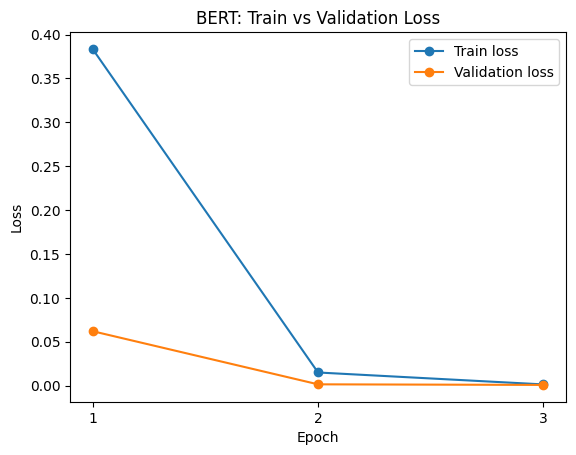

In [13]:
# Convert training records to a table.
# 將訓練紀錄整理成表格。
history = pd.DataFrame(trainer.state.log_history)

# Select the training loss records.
# 取出每一輪訓練的 Loss。
train_history = history.dropna(subset=["loss"])

# Select the validation loss records.
# 取出每一輪驗證的 Loss。
val_history = history.dropna(subset=["eval_loss"])

# Plot the training loss.
# 畫出訓練集 Loss 曲線。
plt.plot(train_history["epoch"], train_history["loss"], marker="o", label="Train loss")

# Plot the validation loss on the same chart.
# 在同一張圖畫出驗證集 Loss 曲線。
plt.plot(val_history["epoch"], val_history["eval_loss"], marker="o", label="Validation loss")

# Set integer ticks for each training epoch.
# 將橫軸設定為每一輪訓練的整數。
plt.xticks(train_history["epoch"])

# Add plot labels and a legend.
# 加上圖表名稱、座標軸名稱與圖例。
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BERT: Train vs Validation Loss")
plt.legend()

# Show the chart.
# 顯示兩條 Loss 曲線。
plt.show()

## Optional｜查看模型預測的 0／1 人數（直接執行）

這裡不是再訓練一次，而是檢視前面 `predict()` 的輸出。


In [14]:
# Count predicted labels in the test set.
# 統計測試資料中各個預測類別的數量。
print("預測為 0／1 的筆數：")
print(pd.Series(predicted).value_counts().sort_index())

# Show the real label counts for comparison.
# 顯示真實標籤的筆數，方便比較。
print("真實的 0／1 筆數：")
print(test_df["label"].value_counts().sort_index())

# Compare with a classifier that always predicts zero.
# 比較「全部猜 0」的簡單基準正確率。
baseline = (test_df["label"] == 0).mean()
print("全部猜 0 的 Accuracy：", round(baseline, 3))


預測為 0／1 的筆數：
0    66
1    34
Name: count, dtype: int64
真實的 0／1 筆數：
label
0    66
1    34
Name: count, dtype: int64
全部猜 0 的 Accuracy： 0.66


## Optional｜重新載入儲存的模型（直接執行）

前面已將最佳模型及 Tokenizer 儲存在 `03_bert_binary_output` 中，**不需要再另存一次**。這裡示範如何從資料夾重新載入，確認模型真的可以使用。

資料夾中的 `checkpoint-...` 是訓練檢查點；`config.json`、`model.safetensors` 與 Tokenizer 相關檔案則可供 `pipeline()` 直接使用。

In [15]:
# Load the saved model from the output folder.
# 從儲存資料夾重新載入微調模型。
saved_classifier = pipeline(
    "text-classification",
    model=settings.output_dir,
    tokenizer=settings.output_dir,
    device=device
)

# Predict one message with the reloaded model.
# 使用重新載入的模型預測一句留言。
text = "我已經確定可以去園遊會。"
results = saved_classifier(text)
print(results)

Device set to use cuda:0


[{'label': 'LABEL_1', 'score': 0.9970338344573975}]


**課堂總結：**上傳 CSV → 讀取留言 → 切分 Train／Validation／Test → 文字轉換 → 微調 BERT → 每輪記錄 Train／Validation Loss → 儲存最佳模型 → 用 Test 計算 Accuracy → 預測新留言。

**補充：**`num_labels=2` 就足以建立二元分類模型；`id2label` 只是讓畫面顯示中文。資料是模擬句型，測試成績可能較樂觀；Validation 用來觀察與選模型，Test 則保留給最後評估。

---

## 從二元分類到多元分類

將這個檔案上傳到 ChatGPT 或其它 AI 平台，然後跟它說：

```log
附件是我的二元分類範例程式。

你幫我將 https://huggingface.co/datasets/Johnson8187/Chinese_Multi-Emotion_Dialogue_Dataset 的資料集整合到附件當中，讓我進行多元分類的訓練。

更新完 .ipynb 之後，取名為 03_BERT_multiclass.ipynb 讓我下載。
```

取得 `03_BERT_multiclass.ipynb` 之後，再複製貼上到 `03` 資料夾，然後重新連到 `Colab server`，再從第一個 cell 開始執行，看看能不能檢視多元分類的過程與結果。